# 學生學習與作業版｜任務 4：描述統計與視覺化

**姓名：** 張孜瑋**學號／組別：** C114118106　**完成日期：** 11/12

**學習目標：** 以描述統計、直方圖和盒鬚圖理解分布與離群值。

本單元與教師版「任務 4」相同標題、資料、教學順序與範例；除了明確標示的作業與填空，其餘教師版教材內容保留。對照重點：程式填空對應教師版「4.2 直方圖」。

### 如何完成
1. 先閱讀觀念與執行資料準備；各單元可以獨立啟動，不需要依賴上一單元的變數。
2. **💻 P 作業**：在指定程式 cell 補上 `____`，可先用提供的 Vibe Coding 提示詞詢問 AI。補完再執行，並執行後面的驗證 cell。未填時出現 `NameError` 是預期現象，先完成填空再繼續。
3. **📝 Q 作業**：查詢 AI、比較教材內容，填寫緊接的文字作答區；請記錄實際提示詞、自己的解釋與查證方式。
4. **🎯 M 小任務**：在任務 4、8、12、16 將前面幾單元整合成可執行的成果。不要只交 AI 回覆，要交實際程式、輸出與自己的解釋。
5. 把 Notebook 存到自己的 Google 雲端硬碟，完成後下載／依教師指示繳交 `.ipynb`；小任務保留輸出、文字與 AI 使用紀錄。

**案例限制：**本資料是公式生成的 60 筆模擬紀錄，不能推論真實學生或因果。缺失與 15 小時值在計分後加入。預測時欄位可得性是假設；全部資料已在前半段探索，後續切出的測試集僅示範流程，不能視為完全獨立的新資料。

**完成檢核：**本單元有 1 項程式填空、2 項 AI 查詢作答；若是任務 4、8、12、16，另外有 1 項整合小任務。請保留自己的輸出、回答和驗證紀錄。


## 共用資料準備
以下在記憶體重建與既有教材相同的資料。執行後可以直接開始本單元；不會覆寫 CSV。


In [1]:
# 匯入套件：numpy 建立隨機資料，pandas 管理表格，pyplot 繪圖
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 固定種子，並維持呼叫順序，以重現原教材的 60 筆模擬資料
rng = np.random.default_rng(42)
n = 60
departments = ["資訊管理", "企業管理", "金融管理"]
# 每個字典鍵是一個欄位；對應的值是 60 名學生的資料
data = {
    "student_id": range(1, n + 1),
    "department": rng.choice(departments, n),
    "sleep_hours": rng.normal(6.7, 1.1, n).round(1),
    "screen_time_hours": rng.normal(5.0, 1.5, n).clip(1, 10).round(1),
    "study_hours": rng.normal(2.5, 1.0, n).clip(0.5, 6).round(1),
    "attendance_rate": rng.normal(88, 8, n).clip(60, 100).round(0),
}
df = pd.DataFrame(data)
# 成績依設定公式與隨機誤差建立；關係來自模擬規則，不能視為因果發現
noise = rng.normal(0, 5, n)
score = (50 + 3 * df["study_hours"] + 2 * df["sleep_hours"]
         - 1.2 * df["screen_time_hours"] + 0.15 * df["attendance_rate"] + noise)
df["quiz_score"] = score.clip(0, 100).round(0)
# 故意在計分後加入資料品質問題；無法從表格還原計分時原始值
df.loc[[5, 17], "sleep_hours"] = np.nan
df.loc[8, "screen_time_hours"] = 15.0
print("模擬資料形狀（列, 欄）：", df.shape)


模擬資料形狀（列, 欄）： (60, 7)


## 4.1 描述統計
**觀念說明：**count 是非缺失筆數，mean 是平均，50% 是中位數。極端值可能影響平均，不能只看單一統計量。


In [2]:
# describe 彙整筆數、平均、標準差、四分位數與最大最小值
display(df[["quiz_score", "sleep_hours", "screen_time_hours"]].describe())
print("總筆數：", len(df), "睡眠有效筆數：", df["sleep_hours"].count())
print("螢幕時間平均／中位數：", df["screen_time_hours"].mean(), df["screen_time_hours"].median())


,quiz_score,sleep_hours,screen_time_hours
count,60.000000,58.000000,60.000000
mean,78.800000,6.682759,4.946667
std,6.681114,0.822307,1.985239
min,63.000000,4.800000,1.800000
25%,75.000000,6.200000,3.600000
50%,80.000000,6.750000,4.700000
75%,82.250000,7.300000,5.625000
max,92.000000,9.100000,15.000000


總筆數： 60 睡眠有效筆數： 58
螢幕時間平均／中位數： 4.946666666666668 4.7


## 📝 學生作業 04-Q1｜AI 查詢與作答：統計量
**任務：**平均數與中位數如何受到極端值影響？以具體數字說明。

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請用少量數字示範平均數與中位數，加入極端值前後各算一次，並說明限制。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 04-Q1 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：ChatGPT   
實際提示詞：請用簡單的數字說明平均數和中位數的差異，並舉例比較加入極端值前後的變化。
- AI 回答重點（請自行整理）：平均數是將所有數值加總後除以資料筆數，容易受到極端值影響。中位數是將資料由小到大排列後，取中間位置的數值，因此通常比較不容易受到極端值影響。
- 我的理解與具體例子：例如五筆資料為 2、3、4、5、6，平均數和中位數都是 4。   
如果把最後一筆改成 100，資料變成 2、3、4、5、100，平均數會變成 22.8，但中位數仍然是 4。   
這代表當資料中有極端值時，平均數可能被拉高，而中位數比較能反映資料中間的位置。
- 查證來源／方式及日期（無法查證請註明）：課程《04_描述統計與視覺化》Notebook，4.1 描述統計。   
查證方式：利用平均數公式手動計算，並與教材中 mean 和 50%（中位數）的定義比較。   
查證日期：2026/11/12。
- 我檢查或修正 AI 回答的地方：極端值會影響平均數，但不一定會讓中位數有很大的變化。因此分析資料時，不能只看平均數，還需要搭配中位數及其他統計量，才能更完整地了解資料。


## 4.2 直方圖
橫軸是分數區間，縱軸為該區間人數。調整 bins 會改變切分方式，不會改變資料；比較不同圖前確認尺度與分箱。


## 💻 學生作業 04-P1｜Vibe Coding 程式填空
**對應教師版：**任務 4「4.2 直方圖」的示範程式。

**任務：**在既有圖表中繪製 quiz_score 的直方圖，排除缺失值，分成 10 箱，保留既有標題和座標軸。

**執行方式：**找到下一個程式儲存格中的 `____`，使用自己撰寫或 AI 建議的程式補齊，保留其他已提供的程式與註解。補完後先執行該 cell，再執行緊接的自動檢查；後續單元內容可能依賴此變數。

**可使用的 Vibe Coding 提示詞：**
```text
我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。
我的任務是：在既有圖表中繪製 quiz_score 的直方圖，排除缺失值，分成 10 箱，保留既有標題和座標軸。
請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。
```
完成後記錄實際使用的提示詞與自己改動的地方。


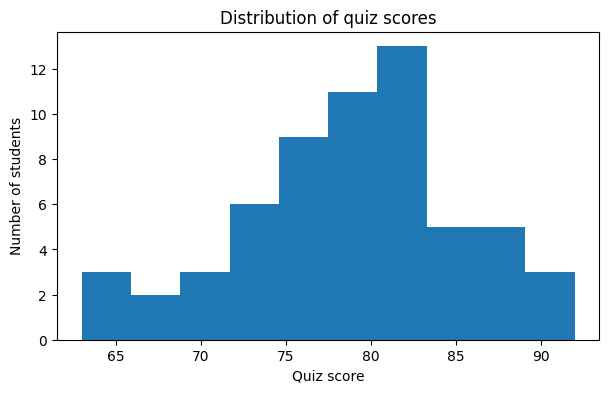

有效成績筆數： 60


In [3]:
# 以英文標籤避免 Colab 缺中文字型；圖形後呼叫 show
plt.figure(figsize=(7, 4))
plt.hist(df["quiz_score"].dropna(), bins=10)  # TODO：以 quiz_score 的非缺失資料畫 bins=10 的直方圖
plt.title("Distribution of quiz scores")
plt.xlabel("Quiz score")
plt.ylabel("Number of students")
plt.show()
print("有效成績筆數：", df["quiz_score"].count())


### ✅ 作業 04-P1｜執行驗證
執行下方程式，並同時檢查上方實際輸出。自動檢查只涵蓋主要條件；如果圖表、說明或資料來源不符任務，仍需人工修正。


In [4]:
assert df["quiz_score"].notna().sum() == 60
print("請人工檢查上方直方圖的標題、軸及 10 個分箱。")


請人工檢查上方直方圖的標題、軸及 10 個分箱。


### ✍️ 作業 04-P1｜我的完成紀錄
- 我實際使用的提示詞（若未使用 AI 請註明）：請協助我使用 Python matplotlib 繪製 quiz_score 的直方圖，排除缺失值並設定 bins=10，保留原本的圖表標題和座標軸。
- 我補上的程式在做什麼：使用 plt.hist() 繪製小考成績的直方圖，透過 dropna() 排除缺失值，再使用 bins=10 將成績分成 10 個區間，觀察學生的成績分布。
- 執行或驗證遇到的問題與修正：先前執行時曾出現 plt is not defined，原因是尚未執行匯入 matplotlib 的程式。後來先執行共用資料準備，確認已匯入繪圖套件並建立 df，再重新執行直方圖程式。
- 檢查結果及我如何確認：確認直方圖有正確顯示標題、成績區間和人數，並設定為 10 個分箱。透過 df["quiz_score"].count() 檢查有效成績筆數，教材中的模擬資料結果為 60 筆，與原始資料筆數一致。

## 📝 學生作業 04-Q2｜AI 查詢與作答：圖形解讀
**任務：**直方圖 bins 改變時，為何外觀會改變？是否代表資料本身改變？

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請解釋直方圖分箱與盒鬚圖各能回答什麼問題，並說明離群點不一定是錯誤。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 04-Q2 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：ChatGPT   
實際提示詞：請解釋 Python 直方圖中的 bins 是什麼，為什麼改變 bins 會讓圖表外觀不同，並比較直方圖與盒鬚圖的用途。
- AI 回答重點（請自行整理）：bins 是直方圖的分箱數量，用來決定資料要分成多少個區間。   
當 bins 較少時，每個區間較大，圖形看起來比較簡單；當 bins 較多時，每個區間較小，可以看到更多分布細節。   
盒鬚圖則主要用來觀察中位數、四分位數、資料分散情況及可能的離群值。
- 我的理解與具體例子：改變 bins 只是改變資料的呈現方式，並不會改變原始資料。  
例如將同樣的 60 筆小考成績分成 5 箱或 10 箱，圖形的長條數量和高度會不同，但學生的成績和資料筆數仍然相同。  
另外，盒鬚圖中出現離群點，也不代表資料一定錯誤，可能是實際存在的特殊情況，需要進一步確認。
- 查證來源／方式及日期（無法查證請註明）：課程《04_描述統計與視覺化》Notebook，4.2 直方圖、4.3 盒鬚圖與極端值，以及延伸示範。  
查證方式：比較 bins=5 和 bins=10 的直方圖，並利用 np.histogram() 檢查各區間的人數加總。  
查證日期：2026/11/12。
- 我檢查或修正 AI 回答的地方：改變 bins 不會改變原始資料，只會影響圖形的呈現方式。另外，直方圖和盒鬚圖的用途不同，直方圖適合觀察分布，盒鬚圖適合觀察資料集中程度及可能的離群值。


## 4.3 盒鬚圖與極端值
盒體反映四分位區間；獨立點是依繪圖規則標示的可能離群值，不等於資料一定錯誤。
**試一試：**將直方圖分箱改為 5，解釋圖形外觀為何改變。


In [ ]:
# dropna 避免缺失值影響繪圖，資料並未從 df 刪除
plt.figure(figsize=(5, 4))
plt.boxplot(df["screen_time_hours"].dropna())
plt.title("Screen time")
plt.ylabel("Hours")
plt.show()
print("大於 10 小時：", (df["screen_time_hours"] > 10).sum())


## 延伸示範：分箱前後數據不變
相同資料用不同 bins 切分，外觀會不同。學生須檢查各箱人數加總與原本有效筆數是否一致，避免把分箱造成的視覺差異誤認為資料變化。


In [ ]:
# numpy 的 histogram 回傳各箱人數及邊界；檢查加總是否一致
valid_scores = df["quiz_score"].dropna()
for bins in [5, 10]:
    counts, edges = np.histogram(valid_scores, bins=bins)
    print("分箱數", bins, "各箱人數", counts, "加總", counts.sum())
    assert counts.sum() == len(valid_scores)


## 本單元學習收束與 AI 使用紀錄

請學生先用自己的話解釋一個關鍵觀念，再指出一個執行結果及驗證方式。記錄：使用的提示詞、AI 回答中檢查或修改的地方、遇到的問題、修正後的證據與本資料限制。

**通用提示詞**：我是 Python 初學者，請逐步協助我完成上面的任務；每段程式加繁體中文註解，說明輸入、處理與輸出，提供兩項可實際執行的驗證，保留原始資料，不要虛構執行結果。


## 🎯 學生小任務 MA｜資料健檢與圖表
**涵蓋：**任務 1～4。這是需要獨立完成、可繳交的整合成果。

### 任務要求
使用 df，以程式列出資料形狀、各欄缺失數、超過 10 小時的筆數；再繪製 quiz_score 直方圖。用文字說明一項品質問題、一項圖表觀察及一項資料限制。不可修改 df。

### 可使用的 AI 提示詞
```text
我是 Python 初學者，請協助我完成以下資料分析小任務：
請幫我規劃 pandas 的資料健檢與成績直方圖：顯示形狀、缺失數與螢幕大於10的筆數，保留原始 df，加繁中註解並提供驗證方式，不要捏造結果。
請拆成小步驟，提供繁體中文教學註解、預期輸出應如何檢查，並提醒不能從這份模擬資料推論因果。
```

### 執行與交付
- 在下一個程式儲存格自行填入程式，先執行本 Notebook 上方的資料準備及必要 cell。若需要更多儲存格可以自行新增。
- 輸出應保留在 Notebook 中；在後面的文字區填寫實際數字與自己的解釋。
- **工具提示：**df.shape、df.isna()、布林篩選、plt.hist。
- 至少記錄一項實際檢查及一項資料限制。交付完成後的 `.ipynb`，含程式、輸出及 AI 使用紀錄。


【1. 資料形狀】
資料形狀： (60, 7)

【2. 各欄位缺失值】
student_id           0
department           0
sleep_hours          2
screen_time_hours    0
study_hours          0
attendance_rate      0
quiz_score           0
dtype: int64

【3. 螢幕使用時間檢查】
超過 10 小時的筆數： 1

【4. 小考成績統計】
平均數： 78.8
中位數： 80.0
有效成績筆數： 60


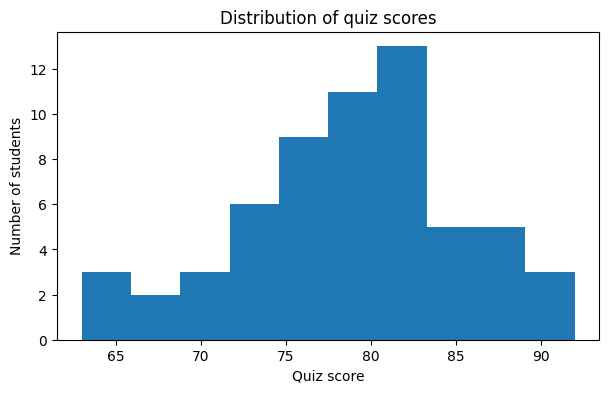


【5. 驗證結果】
檢查通過：資料形狀、缺失值與筆數正確。


In [5]:
# 學生小任務 MA：請在此撰寫你的程式
# 執行前先確認上方資料準備與必要 cell 已執行；可新增其他程式 cell。
# TODO：依任務要求加入程式；完成後執行並保留輸出。

# MA 資料健檢與圖表
# 使用原始 df 進行分析，不修改資料

# 1. 顯示資料形狀
print("【1. 資料形狀】")
print("資料形狀：", df.shape)

# 2. 檢查每個欄位的缺失值
print("\n【2. 各欄位缺失值】")
print(df.isna().sum())

# 3. 計算螢幕使用時間超過 10 小時的筆數
print("\n【3. 螢幕使用時間檢查】")
over_10 = (df["screen_time_hours"] > 10).sum()
print("超過 10 小時的筆數：", over_10)

# 4. 顯示成績描述統計
print("\n【4. 小考成績統計】")
print("平均數：", df["quiz_score"].mean())
print("中位數：", df["quiz_score"].median())
print("有效成績筆數：", df["quiz_score"].count())

# 5. 繪製小考成績直方圖
plt.figure(figsize=(7, 4))
plt.hist(df["quiz_score"].dropna(), bins=10)

plt.title("Distribution of quiz scores")
plt.xlabel("Quiz score")
plt.ylabel("Number of students")

plt.show()

# 6. 驗證資料
print("\n【5. 驗證結果】")

assert df.shape == (60, 7)
assert df["sleep_hours"].isna().sum() == 2
assert over_10 == 1
assert df["quiz_score"].count() == 60

print("檢查通過：資料形狀、缺失值與筆數正確。")


### ✍️ 小任務 MA｜結果與檢核（請雙擊填寫）
- 問題及使用的資料／欄位：本次使用 60 筆模擬學生資料進行資料品質檢查與成績分析。  
主要使用 sleep_hours、screen_time_hours 和 quiz_score 三個欄位，檢查缺失值、螢幕使用時間及小考成績分布。
- 實際輸出與至少一項依據數字的觀察：檢查後發現 sleep_hours 有 2 筆缺失值，screen_time_hours 有 1 筆超過 10 小時，其餘欄位沒有缺失值。  
小考成績的平均數為 78.8 分，中位數為 80 分，代表這份模擬資料的成績中心位置大約在 80 分附近。
- 圖表或模型結果的解讀（依任務要求）：利用直方圖將小考成績分成 10 個區間，可以觀察不同分數範圍的學生人數。  
結果顯示成績較集中在 75～83 分附近，整體分數介於 63～92 分之間。  
直方圖可以幫助我們了解成績分布，但無法單靠圖形判斷影響成績的原因。
- 資料品質、模擬資料或評估限制：資料中有 2 筆睡眠時數缺失，以及 1 筆螢幕使用時間超過案例原本設定的上限。
這些資料需要進一步確認，不能直接認定為錯誤並刪除。
- 驗證方法與結果：利用 df.shape 確認資料有 60 列、7 欄，再使用 df.isna().sum() 檢查各欄位的缺失數量。
透過布林條件計算螢幕使用時間超過 10 小時的筆數，結果為 1 筆。
另外，使用 df["quiz_score"].count() 確認有效成績為 60 筆，並透過 assert 檢查資料形狀和筆數。
- AI 工具、實際提示詞、人工修改與遇到的問題：ChatGPT  
實際提示詞：請協助我使用 Python pandas 和 matplotlib，完成學生資料的品質檢查，包含資料形狀、各欄缺失值、螢幕使用時間超過 10 小時的筆數，以及小考成績直方圖，並提供驗證方式。
人工修改：依照老師的要求，加入繁體中文註解、統計結果及 assert 驗證，並確認程式不會修改原始 df。
- 重新執行是否成功及環境或檔案需求：使用 Google Colab 環境執行。  
需要 numpy、pandas、matplotlib 等套件。   
教材相同的模擬資料與檢查程式已驗證可執行；正式繳交前仍需在自己的 Notebook 重新執行，確認能顯示統計結果與直方圖。
